In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from jaxopt import AndersonAcceleration
import pickle
import optax
import seaborn as sns
from scipy.stats import t as student_t
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple

# Model parameters
m = 2  # Number of mitral neurons (glomeruli)


n_r = 1.850
n_g = 1.868
n_b = 0.642
n_y = 1.562


In [2]:
# Naka-Rushton function

def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

In [3]:

def unpack_theta(theta, m):
    w_osn_r = jnp.array([theta[0], theta[0]])
    w_osn_b = jnp.array([theta[1], theta[1]])
    w_osn_g = jnp.array([theta[2], theta[2]])
    w_osn_y = jnp.array([theta[3], theta[3]])
    w_b_r = jnp.array([theta[4], theta[4]])
    w_b_g = jnp.array([theta[5], theta[5]])
    w_b_y = jnp.array([theta[6], theta[6]])
    w_r_y = jnp.array([theta[7], theta[7]])
    w_r_g = jnp.array([theta[8], theta[8]])
    alpha = jnp.array([theta[9], theta[9]])
    # Build 2x2 matrices so all elements are same type (avoids JAX shape error)
    zero = jnp.asarray(0.0)
    wr = jnp.asarray(theta[10])
    wy = jnp.asarray(theta[11])
    W_g_r = jnp.stack([jnp.stack([zero, wr]), jnp.stack([wr, zero])])
    W_g_y = jnp.stack([jnp.stack([zero, wy]), jnp.stack([wy, zero])])
    n_g_val = theta[12]
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val


# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g)

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r, n_b):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    # Pass n_g_val as explicit arg so JAX can differentiate w.r.t. it (closed-over values break custom_vjp)
    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_g_val):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g_val)

    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_g_val)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r, n_b, n_y):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

In [4]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_214_2_points_final.pkl'

with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

Loaded theta_opt with shape: (214, 13)
Number of samples: 214
Number of parameters per sample: 13


In [5]:
# Define the dynamics function F(s, theta, x, m) with different n values
# State vector s = [r, g, y]
def F(s, theta, x, m, n_r=1.850, n_b=0.642, n_y=1.562):
    """
    Dynamics function that computes the next state from current state s.
    """
    # Unpack state vector
    r = s[:m]
    g = s[m:2*m]
    y = s[2*m:3*m]

    # Unpack parameters
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, n_g_val = unpack_theta(theta, m)

    # Compute b (doesn't depend on state, only on input)
    b = nr(w_osn_b * alpha * x, n=n_b)

    # Compute new r from current g
    r_new = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)

    # Compute new g from current r
    g_new = nr(w_osn_g * alpha * x - w_b_g * b + w_r_g * r, n=n_g_val)

    # Compute new y from g_new and r_new
    y_new = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g_new + w_r_y * r_new, n=n_y)

    # Return concatenated state vector
    s_prime = jnp.concatenate([r_new, g_new, y_new])
    return s_prime

# Compute Jacobian matrix J = dF/ds at the fixed point s_star
def compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_y):
    # Create a function that only depends on s (for JAX differentiation)
    def F_s(s):
        return F(s, theta, x, m, n_r, n_b, n_y)

    # jax.jacobian computes the Jacobian matrix: J[i,j] = dF_i/ds_j
    J = jax.jacobian(F_s)(s_star)
    return J

# Compute matrix A and check stability
def compute_stability(F, s_star, theta, x, m, tau=1.0, n_r=2.333, n_b=0.9, n_y=1.562):
    n = s_star.shape[0]
    I = jnp.eye(n)
    J = compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_y)
    A = (1 / tau) * (J - I)

    eigenvalues = jnp.linalg.eigvals(A)
    eigenvalues_np = np.array(eigenvalues)

    # Check stability - all eigenvalues must have negative real parts
    real_parts = np.real(eigenvalues_np)
    is_stable = np.all(real_parts < 0.0)

    return {
        'J': J,
        'A': A,
        'eigenvalues': eigenvalues_np,
        'is_stable': is_stable,
        'real_parts': real_parts,
        'imag_parts': np.imag(eigenvalues_np)
    }


In [6]:
# Use a subset of samples for faster analysis
n_samples_to_analyze = 214 #theta_opt.shape[0]
theta_subset = theta_opt[:n_samples_to_analyze]
print(f"\nUsing {n_samples_to_analyze} samples for analysis")


Using 214 samples for analysis


# 13. Compute Hessian (2 op)

In [7]:
x = jnp.array([0.5, 0.5])

Processing 214 samples...
  Sample 1/214...
  Sample 101/214...
  Sample 201/214...
Completed processing 214 samples


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


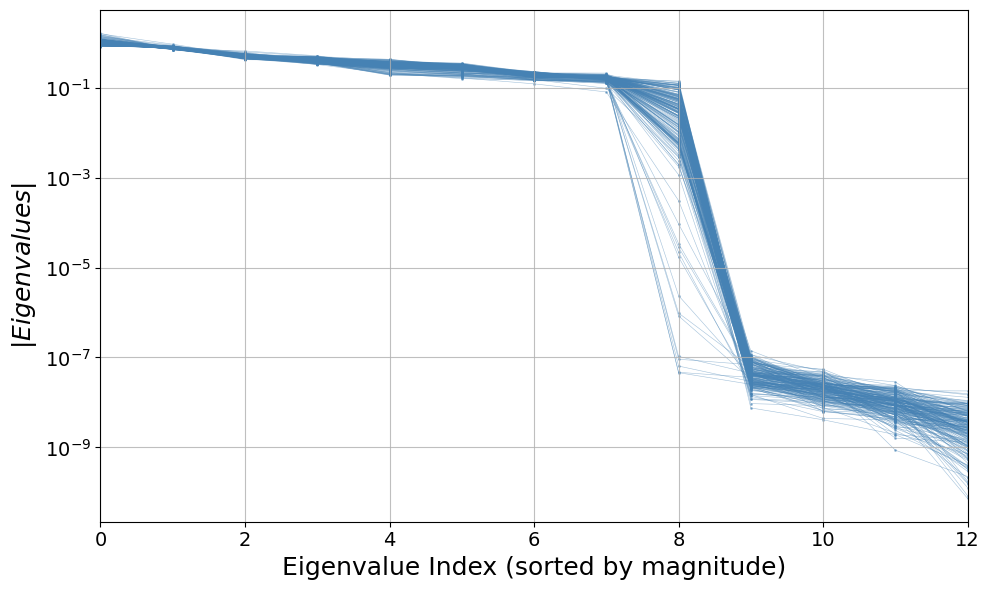

In [8]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_y)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

theta_samples = theta_opt
near_zero_threshold = 1e-5

print(f"Processing {theta_samples.shape[0]} samples...")
n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]
all_eigenvalues = np.zeros((n_samples, n_params))
all_eigenvectors = np.zeros((n_samples, n_params, n_params))

# Process all samples
for i in range(n_samples):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    # Compute and sort eigenvalues in one step
    eigenvalues_H = np.array(jnp.linalg.eigh(H).eigenvalues)
    eigenvectors_H = np.array(jnp.linalg.eigh(H).eigenvectors)
    all_eigenvalues[i, :] = np.abs(eigenvalues_H[np.argsort(np.abs(eigenvalues_H))[::-1]])
    all_eigenvectors[i, :, :] = eigenvectors_H[:, np.argsort(np.abs(eigenvalues_H))[::-1]]

print(f"Completed processing {n_samples} samples")

# Visualise
fig, ax = plt.subplots(figsize=(10, 6))
n_params = all_eigenvalues.shape[1]

# Plot individual samples (light, transparent)
ax.semilogy(all_eigenvalues.T, 'o-', ms=1, lw=0.4, alpha=0.5, color='steelblue', zorder=1)

# Plot statistics
ax.set_xlabel('Eigenvalue Index (sorted by magnitude)', fontsize=18)
ax.set_ylabel('$|Eigenvalues|$', fontsize=18)
ax.set_xlim(-0.5, n_params)
ax.tick_params(axis='both', labelsize=14, direction='out')
ax.grid(True, alpha=0.8)
ax.set_xlim(0, 12)
plt.tight_layout()
plt.savefig(f'Figures_final/two_op_hessian_eigenvalues.eps')
plt.show()

In [9]:
all_eigenvectors.shape

(214, 13, 13)

In [10]:
# Plot eigenvectors for eigenvalue rank by |lambda| (overlay all samples)
eig_rank = 8  # index in eigenvalues sorted by magnitude (0-based)
max_samples = None  # set to int to cap

n_samples = len(all_eigenvalues)
sample_indices = range(n_samples) if max_samples is None else range(min(n_samples, max_samples))

plotted = 0

for sample_idx in sample_indices:
    eigvals = np.asarray(all_eigenvalues[sample_idx])
    eigvecs = np.asarray(all_eigenvectors[sample_idx])  # columns are eigenvectors

    if eigvals.size <= eig_rank:
        print(f"Sample {sample_idx}: only {eigvals.size} eigenvalues; skipping rank {eig_rank}")
        continue

    sorted_idx = np.argsort(np.abs(eigvals))
    k = int(sorted_idx[eig_rank])
    v = eigvecs[:, k]


In [11]:
v = jnp.zeros(n_params)
v = v.at[12].set(1)
v@v.T
v[:, None] * v[None, :]

Array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1.]],      dtype=float32)

In [22]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_y)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]

v = jnp.zeros(n_params)
v = v.at[12].set(-1)

x_collect = []
for i in range(n_samples):
#for i in range(3):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    H1 = (jnp.eye(n_params) - v[:, None] * v[None, :]) @ H @ (jnp.eye(n_params) - v[:, None] * v[None, :])
    H2 = (jnp.eye(n_params) - v[:, None] * v[None, :]) @ H

    x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6) @ H2 @ v #pseudo inverse
    x_collect.append(x_free_1 + v)

x_collect = jnp.array(x_collect)




  Sample 1/214...


/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_897/726116112.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6) @ H2 @ v #pseudo inverse
/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_897/726116112.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6) @ H2 @ v #pseudo inverse
/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_897/726116112.py:27: DeprecationWarning: The rcond argument for linalg.pinv is deprecated using it will soon raise an error. To prepare for future releases, and suppress this warning, please use rtol instead.
  x_free_1 = - jnp.linalg.pinv(H1, rcond=1e-6) @ H2 

  Sample 101/214...
  Sample 201/214...


In [13]:
x_collect[2:].shape

(212, 13)

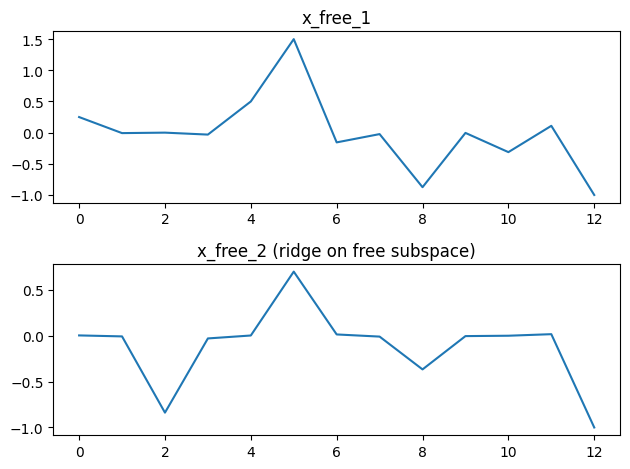

In [14]:
v = jnp.zeros(n_params)
v = v.at[12].set(-1)

# Projector onto the "free" subspace (orthogonal to v)
P = jnp.eye(n_params) - v[:, None] * v[None, :]

# let H1 = P^T H P (P is symmetric)
H1 = P @ H @ P

# let H2 = P H
H2 = P @ H

b = H2 @ v

# Baseline: pseudoinverse solution in the free subspace
x_free_1 = - jnp.linalg.pinv(H1, rtol=1e-8) @ b

####################
# Proper regularization for this construction:
# - H1 is singular along v by design (because of P)
# - adding eps*I changes the constrained direction too
# So we ridge only on the free subspace via (ridge * P)
# and solve with lstsq for robustness. 
eps = 1e-5
scale = (jnp.linalg.norm(H1, ord="fro") / jnp.sqrt(n_params)) + 1e-12
ridge = eps * scale
A = H1 + ridge * P

x_free_2 = - jnp.linalg.lstsq(A, b, rcond=None)[0]

# Ensure x is in the free subspace (numerical cleanup)
x_free_2 = P @ x_free_2

fig, axs = plt.subplots(2, 1)
axs[0].plot(x_free_1 + v)
axs[0].set_title("x_free_1")
axs[1].plot(x_free_2 + v)
axs[1].set_title("x_free_2 (ridge on free subspace)")

plt.tight_layout()
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


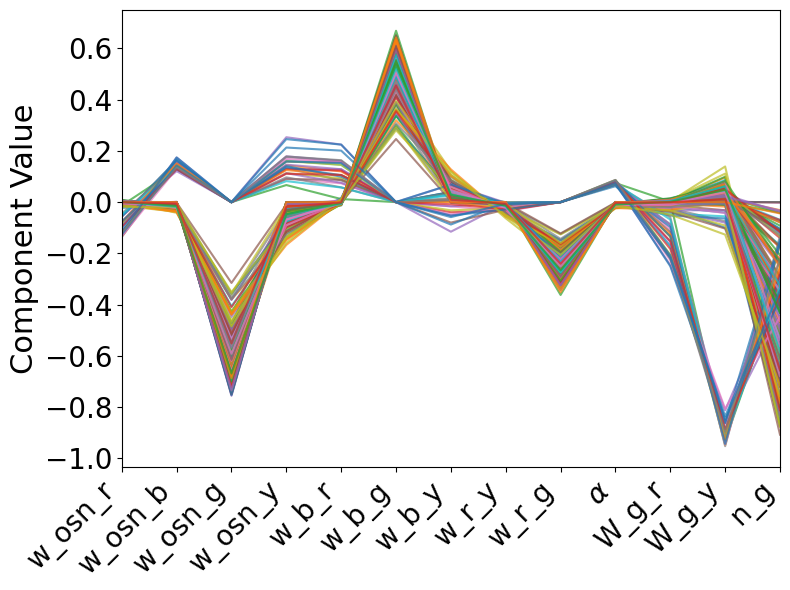

In [23]:
#plot all x_collect, each row is a different colour

x_collect = x_collect / jnp.linalg.norm(x_collect, axis=1, keepdims=True)

param_labels = [
    'w_osn_r', 'w_osn_b', 'w_osn_g', 'w_osn_y',
    'w_b_r', 'w_b_g', 'w_b_y', 'w_r_y', 'w_r_g',
    r"$\alpha$", 'W_g_r', 'W_g_y', 'n_g',
]

x_collect_np = np.array(x_collect)
indices = np.arange(len(param_labels))

plt.figure(figsize=(8, 6))
for row_idx in range(x_collect_np.shape[0]):
    plt.plot(indices, x_collect_np[row_idx], alpha=0.7)

plt.ylabel("Component Value", fontsize=22)
plt.xlim(-0, 12)
plt.xticks(range(len(param_labels)), param_labels, rotation=45, ha='right', fontsize=20)
plt.yticks(fontsize=20)
plt.tight_layout()
plt.savefig(f'Figures_final/x_collect_all.eps')
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


187 / 214 vectors match filter


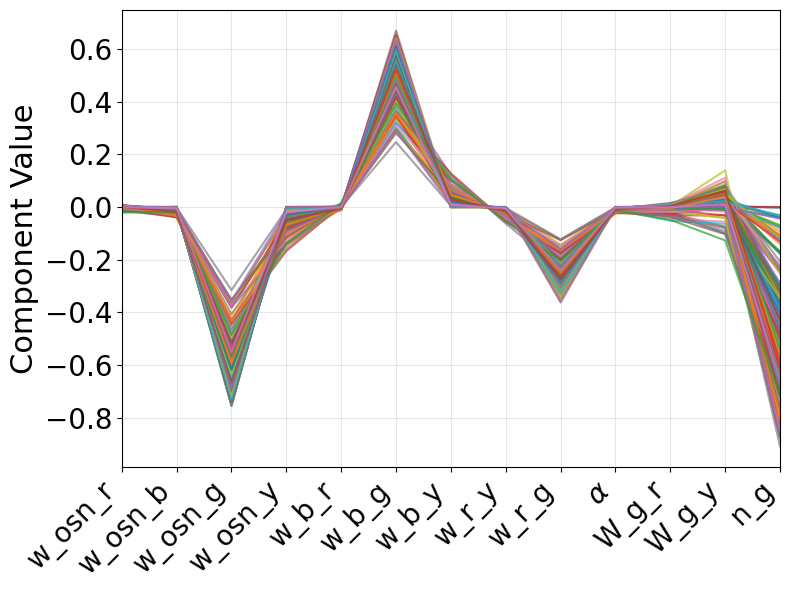

In [35]:
# Vectors with w_b_g < -0.1 and positive n_g
idx_w_b_g = param_labels.index('w_b_g')
idx_n_g = param_labels.index('n_g')

mask = (x_collect_np[:, idx_w_b_g] > 0.1) & (x_collect_np[:, idx_n_g] < 0)
x_collect_filtered = x_collect_np[mask]
print(f'{x_collect_filtered.shape[0]} / {x_collect_np.shape[0]} vectors match filter')

plt.figure(figsize=(8, 6))
for row_idx in range(x_collect_filtered.shape[0]):
    plt.plot(indices, x_collect_filtered[row_idx], alpha=0.7)

plt.ylabel("Component Value", fontsize=22)
plt.xlim(-0, 12)
plt.xticks(range(len(param_labels)), param_labels, rotation=45, ha='right', fontsize=20)
plt.yticks(fontsize=20)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('Figures_final/x_collect_wbg_ng.eps')
plt.show()

In [17]:
# Quadratic cost x̂^T H x̂ for filtered directions (w_b_g < -0.1, n_g > 0)
# Use unit directions (same as x_collect_filtered / scatter x̂·ĝ)
filtered_indices = np.where(mask)[0]
n_directions = len(filtered_indices)
print(f"Computing x̂^T H x̂ for {n_directions} filtered directions...")

v = jnp.zeros(n_params)
v = v.at[12].set(1)
P = jnp.eye(n_params) - v[:, None] * v[None, :]

xTHx_values = []
for j in range(n_directions):
    if j % 50 == 0:
        print(f"  {j+1}/{n_directions}...")

    i = filtered_indices[j]
    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    H1 = P @ H @ P
    H2 = P @ H
    x_dir = -jnp.linalg.pinv(H1, rtol=1e-6) @ (H2 @ v) + v
    x_unit = x_dir / jnp.linalg.norm(x_dir)
    xTHx_values.append(float(x_unit @ H @ x_unit))

xTHx_values = np.array(xTHx_values)
print(f"x̂^T H x̂ ({n_directions} filtered): min={xTHx_values.min():.4e}, max={xTHx_values.max():.4e}, median={np.median(xTHx_values):.4e}")



Computing x̂^T H x̂ for 187 filtered directions...
  1/187...
  51/187...
  101/187...
  151/187...
x̂^T H x̂ (187 filtered): min=-1.6533e-01, max=-7.9768e-08, median=-3.4229e-02


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


ŝ·ĝ (187 filtered, x=0.5): mean=-4.451e-02, std=3.699e-02, min=-1.728e-01, max=5.696e-03


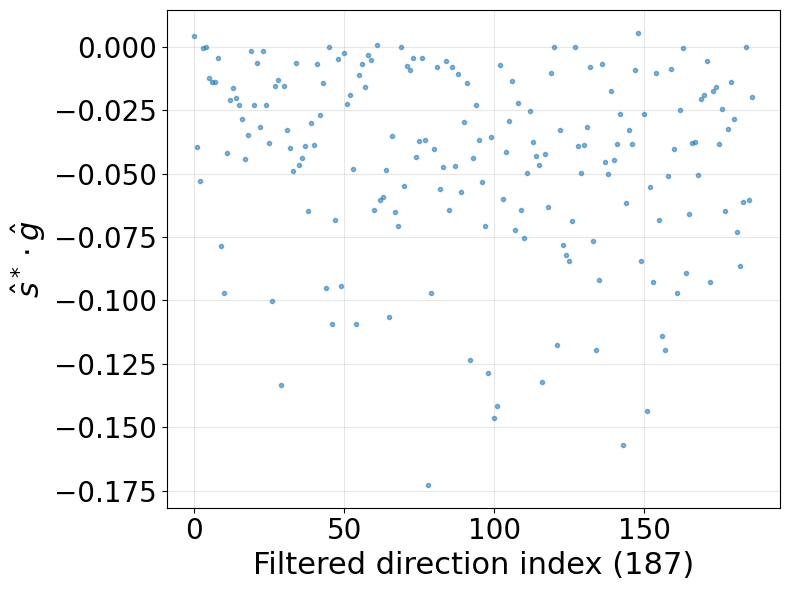

In [30]:
# Gradient dot x̂·ĝ vs filtered direction index (matched θ* and unit directions)
n_retained = len(filtered_indices)
assert n_retained == x_collect_filtered.shape[0] == len(xTHx_values)

theta_matched_jax = jnp.asarray(theta_opt[filtered_indices])

X_rows = np.asarray(x_collect_filtered)
X_hat_rows = X_rows / np.maximum(np.linalg.norm(X_rows, axis=1, keepdims=True), 1e-30)

def make_batched_grad(x_osn):
    def y_output_sum(theta):
        r, g, b, y = mitral_output(theta, x_osn, m, n_r, n_b, n_y)
        return jnp.sum(y)
    return jax.jit(jax.vmap(jax.grad(y_output_sum)))

def compute_dots_matched(x_osn):
    G_matched = np.asarray(make_batched_grad(x_osn)(theta_matched_jax))
    G_hat_matched = G_matched / np.maximum(np.linalg.norm(G_matched, axis=1, keepdims=True), 1e-30)
    return np.sum(X_hat_rows * G_hat_matched, axis=1)

x_osn = jnp.array([0.5, 0.5])
dir_index = np.arange(n_retained)

dots_matched = compute_dots_matched(x_osn)
print(
    f'ŝ·ĝ ({n_retained} filtered, x=0.5): '
    f'mean={np.mean(dots_matched):.3e}, std={np.std(dots_matched):.3e}, '
    f'min={dots_matched.min():.3e}, max={dots_matched.max():.3e}'
)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(dir_index, dots_matched, '.', ms=6, alpha=0.55, color='C0')
ax.set_xlabel(rf'Filtered direction index ({n_retained})', fontsize=22)
ax.set_ylabel(r'$\hat{s}^* \cdot \hat{g}$', fontsize=22)
ax.tick_params(axis='both', labelsize=20, direction='out')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('Figures_final/x_collect_filtered_gradient_dots.eps')
plt.show()


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


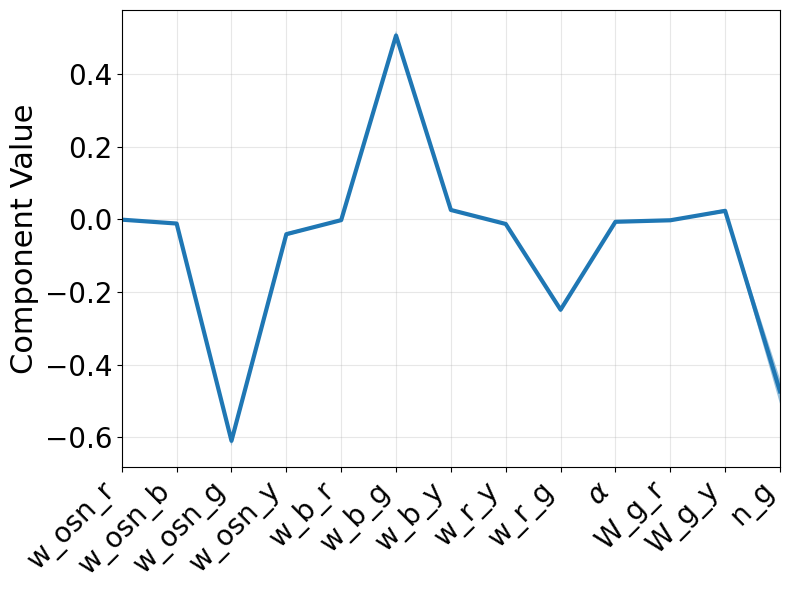

In [34]:
# Mean component profile with 95% CI (w_b_g < -0.1, n_g > 0 filtered directions)
import matplotlib.colors as mcolors

def _lighter_fill_color(color, blend=0.55):
    """Blend matplotlib color toward white for CI shading."""
    cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    if isinstance(color, str) and color.startswith("C") and color[1:].isdigit():
        rgb = mcolors.to_rgb(cycle[int(color[1:]) % len(cycle)])
    else:
        rgb = mcolors.to_rgb(color)
    return tuple(x + blend * (1.0 - x) for x in rgb)

X = np.asarray(x_collect_filtered)  # filtered directions only
n_rows, n_params = X.shape
param_idx = np.arange(n_params)

# Component-wise mean and 95% CI from x_collect_filtered only
mean_components = X.mean(axis=0)
if n_rows > 1:
    sem_components = X.std(axis=0, ddof=1) / np.sqrt(n_rows)
    ci_half = sem_components * student_t.ppf(0.975, n_rows - 1)
else:
    ci_half = np.zeros(n_params)
ci_lower = mean_components - ci_half
ci_upper = mean_components + ci_half

color = "C0"
fill_color = _lighter_fill_color(color)

fig, ax = plt.subplots(figsize=(8, 6))
ax.fill_between(
    param_idx,
    ci_lower,
    ci_upper,
    color=fill_color,
    edgecolor="none",
    zorder=1,
)
ax.plot(param_idx, mean_components, color=color, linewidth=3, zorder=2)
ax.set_ylabel("Component Value", fontsize=22)
ax.set_xlim(-0, 12)
ax.set_xticks(range(len(param_labels)))
ax.set_xticklabels(param_labels, rotation=45, ha="right", fontsize=20)
ax.tick_params(axis="both", labelsize=20, direction="out")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("Figures_final/x_collect_average.eps")
plt.show()

x_collect_average = np.asarray(mean_components, dtype=float)

# Step along delta theta


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


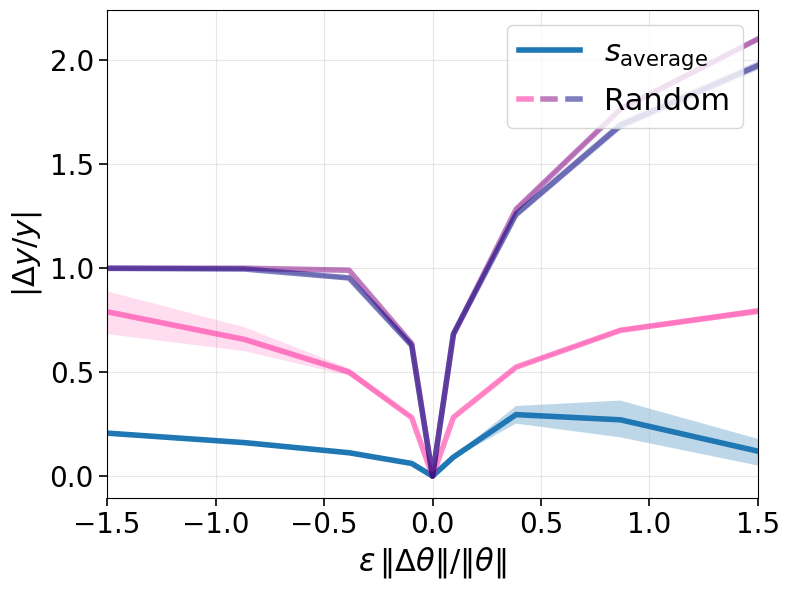

In [32]:
e = np.arange(-2, 2 + 0.2, 0.5)
n_samples = theta_opt.shape[0]

# OSN input (do not use `x` — it may be overwritten by x_collect / x^T H x cells)
x_osn = jnp.array([0.5, 0.5])

theta_opt_subset = jnp.array(theta_opt[:n_samples])
key = jax.random.PRNGKey(5)

def _mitral_single(theta):
    return mitral_output(theta, x_osn, m, n_r, n_b, n_y)

mitral_output_batch = jax.jit(jax.vmap(_mitral_single))

_, _, _, y_baseline = mitral_output_batch(theta_opt_subset)
y_baseline = np.array(y_baseline)

norm_theta_all = np.linalg.norm(theta_opt_subset, axis=1)
mean_norm_theta = np.mean(norm_theta_all)

# x_collect_average (mean filtered direction) + three random directions
mean_direction = jnp.array(x_collect_average)
mean_direction = mean_direction / jnp.linalg.norm(mean_direction)
n_random = 3

x_directions = [
    (r"$s_{\mathrm{average}}$", mean_direction),
]

# Match x_collect construction: unit displacement along n_g (index 12), then normalise
idx_n_g = theta_opt_subset.shape[1] - 1

random_directions = []
for _ in range(n_random):
    key, subkey = jax.random.split(key)
    random_dir = jnp.zeros(theta_opt_subset.shape[1])
    random_dir = random_dir.at[:idx_n_g].set(
        jax.random.normal(subkey, (idx_n_g,))
    )
    random_dir = random_dir.at[idx_n_g].set(1.0)
    random_dir = random_dir / jnp.linalg.norm(random_dir)
    random_directions.append(random_dir)


def _lighter_fill_color(color, blend=0.55):
    """Blend matplotlib color toward white for CI shading."""
    import matplotlib.colors as mcolors

    cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    if isinstance(color, str) and color.startswith("C") and color[1:].isdigit():
        rgb = mcolors.to_rgb(cycle[int(color[1:]) % len(cycle)])
    else:
        rgb = mcolors.to_rgb(color)
    return tuple(x + blend * (1.0 - x) for x in rgb)



opt_colors = [f"C{i}" for i in range(len(x_directions))]
random_colors = ["deeppink", "purple", "navy"]

directions = [
    (label, direction, opt_colors[i])
    for i, (label, direction) in enumerate(x_directions)
]
for r, direction in enumerate(random_directions):
    directions.append(("_nolegend_", direction, random_colors[r]))


def plot_stepping(ax, direction, color, alpha=1.0):
    y_save = []
    for i in range(len(e)):
        theta_step = theta_opt_subset + e[i] * direction
        _, _, _, y = mitral_output_batch(theta_step)
        y_save.append(np.array(y))
    y_array = np.array(y_save)

    theta_ratio = np.array(
        [e[i] * (np.linalg.norm(e[i] * direction) / mean_norm_theta) for i in range(len(e))]
    )
    y0_baseline = y_baseline[:, 0]
    rel0 = np.where(
        np.abs(y0_baseline) > 1e-12,
        (y_array[:, :, 0] - y0_baseline) / y0_baseline,
        y_array[:, :, 0] - y0_baseline,
    )
    abs_rel0 = np.abs(rel0)
    theta_ratio_expanded = np.repeat(theta_ratio, n_samples)
    fill_color = _lighter_fill_color(color)

    sns.lineplot(
        x=theta_ratio_expanded,
        y=abs_rel0.ravel(),
        ax=ax,
        color=color,
        errorbar=("ci", 95),
        legend=False,
        linewidth=0,
        err_kws={
            "facecolor": fill_color,
            "edgecolor": "none",
            "alpha": 0.65 * alpha,
        },
    )
    sns.lineplot(
        x=theta_ratio_expanded,
        y=abs_rel0.ravel(),
        ax=ax,
        color=color,
        errorbar=None,
        legend=False,
        linewidth=4,
        alpha=alpha,
    )


fig, ax = plt.subplots(figsize=(8, 6))

for label, direction, color in directions:
    plot_stepping(
        ax,
        direction,
        color,
        alpha=0.5 if label == "_nolegend_" else 1.0,
    )

ax.set_xlim(-1.5, 1.5)
ax.set_xticks(np.arange(-1.5, 1.51, 0.5))
ax.set_xlabel(
    r"$\epsilon \, \|\Delta \theta\| / \|\theta\|$",
    fontsize=22,
    fontweight="bold",
)
ax.set_ylabel(r"$|\Delta y / y|$", fontsize=22, fontweight="bold")
ax.grid(True, alpha=0.3)
ax.tick_params(
    axis="both",
    which="major",
    direction="out",
    top=False,
    right=False,
    bottom=True,
    left=True,
    labelsize=20,
    width=1.2,
    length=6,
)

opt_handles = [Line2D([0], [0], color=c, lw=4) for c in opt_colors]
random_handles = tuple(
    Line2D([0], [0], color=c, lw=4, alpha=0.5) for c in random_colors
)
opt_labels = [label for label, _, _ in directions if label != "_nolegend_"]
ax.legend(
    handles=opt_handles + [random_handles],
    labels=opt_labels + ["Random"],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    fontsize=22,
    loc="upper right",
)


plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.tight_layout()
plt.savefig("Figures_final/step_in_x_star_2.eps")
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


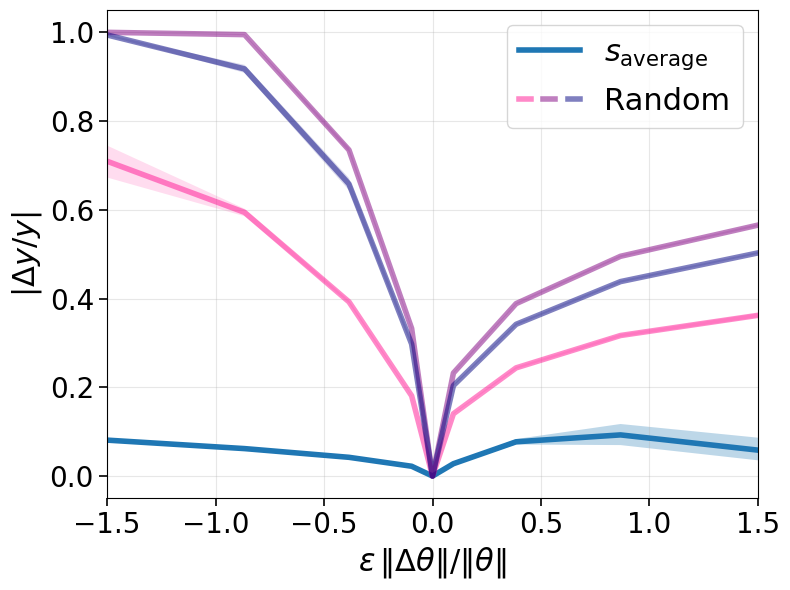

In [33]:
e = np.arange(-2, 2 + 0.2, 0.5)
n_samples = theta_opt.shape[0]

# OSN input (do not use `x` — it may be overwritten by x_collect / x^T H x cells)
x_osn = jnp.array([1, 1])

theta_opt_subset = jnp.array(theta_opt[:n_samples])
key = jax.random.PRNGKey(5)

def _mitral_single(theta):
    return mitral_output(theta, x_osn, m, n_r, n_b, n_y)

mitral_output_batch = jax.jit(jax.vmap(_mitral_single))

_, _, _, y_baseline = mitral_output_batch(theta_opt_subset)
y_baseline = np.array(y_baseline)

norm_theta_all = np.linalg.norm(theta_opt_subset, axis=1)
mean_norm_theta = np.mean(norm_theta_all)

# x_collect_average (mean filtered direction) + three random directions
mean_direction = jnp.array(x_collect_average)
mean_direction = mean_direction / jnp.linalg.norm(mean_direction)
n_random = 3

x_directions = [
    (r"$s_{\mathrm{average}}$", mean_direction),
]

# Match x_collect construction: unit displacement along n_g (index 12), then normalise
idx_n_g = theta_opt_subset.shape[1] - 1

random_directions = []
for _ in range(n_random):
    key, subkey = jax.random.split(key)
    random_dir = jnp.zeros(theta_opt_subset.shape[1])
    random_dir = random_dir.at[:idx_n_g].set(
        jax.random.normal(subkey, (idx_n_g,))
    )
    random_dir = random_dir.at[idx_n_g].set(1.0)
    random_dir = random_dir / jnp.linalg.norm(random_dir)
    random_directions.append(random_dir)


def _lighter_fill_color(color, blend=0.55):
    """Blend matplotlib color toward white for CI shading."""
    import matplotlib.colors as mcolors

    cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    if isinstance(color, str) and color.startswith("C") and color[1:].isdigit():
        rgb = mcolors.to_rgb(cycle[int(color[1:]) % len(cycle)])
    else:
        rgb = mcolors.to_rgb(color)
    return tuple(x + blend * (1.0 - x) for x in rgb)



opt_colors = [f"C{i}" for i in range(len(x_directions))]
random_colors = ["deeppink", "purple", "navy"]

directions = [
    (label, direction, opt_colors[i])
    for i, (label, direction) in enumerate(x_directions)
]
for r, direction in enumerate(random_directions):
    directions.append(("_nolegend_", direction, random_colors[r]))


def plot_stepping(ax, direction, color, alpha=1.0):
    y_save = []
    for i in range(len(e)):
        theta_step = theta_opt_subset + e[i] * direction
        _, _, _, y = mitral_output_batch(theta_step)
        y_save.append(np.array(y))
    y_array = np.array(y_save)

    theta_ratio = np.array(
        [e[i] * (np.linalg.norm(e[i] * direction) / mean_norm_theta) for i in range(len(e))]
    )
    y0_baseline = y_baseline[:, 0]
    rel0 = np.where(
        np.abs(y0_baseline) > 1e-12,
        (y_array[:, :, 0] - y0_baseline) / y0_baseline,
        y_array[:, :, 0] - y0_baseline,
    )
    abs_rel0 = np.abs(rel0)
    theta_ratio_expanded = np.repeat(theta_ratio, n_samples)
    fill_color = _lighter_fill_color(color)

    sns.lineplot(
        x=theta_ratio_expanded,
        y=abs_rel0.ravel(),
        ax=ax,
        color=color,
        errorbar=("ci", 95),
        legend=False,
        linewidth=0,
        err_kws={
            "facecolor": fill_color,
            "edgecolor": "none",
            "alpha": 0.65 * alpha,
        },
    )
    sns.lineplot(
        x=theta_ratio_expanded,
        y=abs_rel0.ravel(),
        ax=ax,
        color=color,
        errorbar=None,
        legend=False,
        linewidth=4,
        alpha=alpha,
    )


fig, ax = plt.subplots(figsize=(8, 6))

for label, direction, color in directions:
    plot_stepping(
        ax,
        direction,
        color,
        alpha=0.5 if label == "_nolegend_" else 1.0,
    )

ax.set_xlim(-1.5, 1.5)
ax.set_xticks(np.arange(-1.5, 1.51, 0.5))
ax.set_xlabel(
    r"$\epsilon \, \|\Delta \theta\| / \|\theta\|$",
    fontsize=22,
    fontweight="bold",
)
ax.set_ylabel(r"$|\Delta y / y|$", fontsize=22, fontweight="bold")
ax.grid(True, alpha=0.3)
ax.tick_params(
    axis="both",
    which="major",
    direction="out",
    top=False,
    right=False,
    bottom=True,
    left=True,
    labelsize=20,
    width=1.2,
    length=6,
)

opt_handles = [Line2D([0], [0], color=c, lw=4) for c in opt_colors]
random_handles = tuple(
    Line2D([0], [0], color=c, lw=4, alpha=0.5) for c in random_colors
)
opt_labels = [label for label, _, _ in directions if label != "_nolegend_"]
ax.legend(
    handles=opt_handles + [random_handles],
    labels=opt_labels + ["Random"],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    fontsize=22,
    loc="upper right",
)


plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.tight_layout()
plt.savefig("Figures_final/step_in_x_star_3.eps")
plt.show()